# Part G — Diagonalization

**Final Project: The Linear Algebra Behind AI — A Regression Problem**

Once a matrix is diagonalized, keeping only the most important directions becomes a simple, principled way to reduce dimensionality.

---
**Student name:** _______________________   **Date:** _______________________

---


**What to do:** Diagonalize your matrix from Part F (C = VΛV⁻¹, or C = VΛVᵀ if symmetric) and use it to reduce dimensionality.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

url = "https://raw.githubusercontent.com/eskups04/AI101-Dataset/main/ai_student_impact_dataset.csv"
df = pd.read_csv(url)

feature_names = [
    "Weekly_GenAI_Hours",
    "Traditional_Study_Hours",
    "Tool_Diversity",
    "Anxiety_Level_During_Exams",
]

X = df[feature_names].to_numpy(dtype=float)
y = df["Skill_Retention_Score"].to_numpy(dtype=float)

# 1. Reproducible 80/20 train-test split FIRST
rng = np.random.default_rng(42)
n = X.shape[0]
perm = rng.permutation(n)
train_size = int(0.8 * n)
train_idx, test_idx = perm[:train_size], perm[train_size:]

# 2. Fit standardization strictly on training data
mu = X[train_idx].mean(axis=0)
sigma = X[train_idx].std(axis=0)
sigma_safe = np.where(sigma == 0, 1.0, sigma)
S = np.diag(1.0 / sigma_safe)
X_transformed = (X - mu) @ S

X_train, X_test = X_transformed[train_idx], X_transformed[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# 3. Compute training covariance C and sorted eigenpairs
C = np.cov(X_train, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(C)
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

print("Setup complete! C shape:", C.shape, "| X_train shape:", X_train.shape)

Setup complete! C shape: (4, 4) | X_train shape: (40000, 4)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

In [3]:
# Build V (eigenvector matrix) and Lambda (diagonal eigenvalue matrix)
V = eigvecs
Lambda = np.diag(eigvals)

# Verify V^T V = I (orthogonality) and that V Lambda V^T reconstructs C
reconstructed_C = V @ Lambda @ V.T
print("V^T V = I ?", np.allclose(V.T @ V, np.eye(V.shape[0])))
print("Reconstruction matches C ?", np.allclose(C, reconstructed_C))

V^T V = I ? True
Reconstruction matches C ? True


In [4]:
# Choose k = smallest number of components explaining >= 95% of variance
explained_var_ratio = eigvals / eigvals.sum()
cum_var = np.cumsum(explained_var_ratio)
k = int(np.searchsorted(cum_var, 0.95) + 1)
print(f"k = {k}, cumulative variance explained = {cum_var[k-1]*100:.2f}%")

k = 4, cumulative variance explained = 100.00%


In [5]:
# Project the data onto the top-k eigenvectors (a linear transformation!)
V_k = V[:, :k]
Z_train = X_train @ V_k
Z_test = X_test @ V_k
print("Z_train shape:", Z_train.shape, "| Z_test shape:", Z_test.shape)

Z_train shape: (40000, 4) | Z_test shape: (10000, 4)


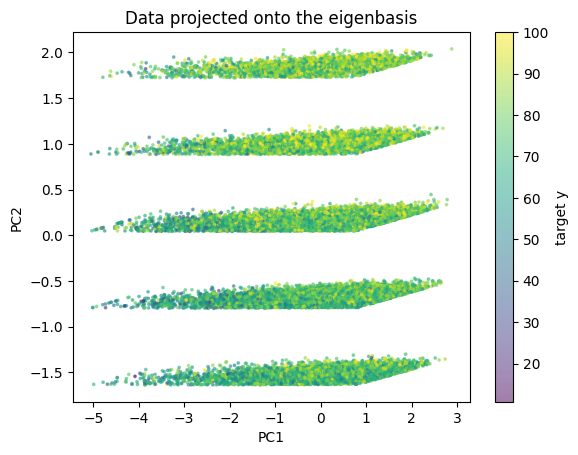

In [6]:
# Optional: visualize your data projected onto the first two principal components
plt.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="viridis", s=3, alpha=0.5)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.colorbar(label="target y")
plt.title("Data projected onto the eigenbasis")
plt.show()

### Answer these in your report

**Q25.** Write your diagonalization in the form C = VΛV⁻¹ (or VΛVᵀ). What are the dimensions of V and Λ?

> *Your answer:* _The diagonalization of our covariance matrix is expressed as:_
_Cᵀ = VΛVᵀ_<br>
>
> _We use VΛVᵀ instead of VΛV⁻¹ because our covariance matrix is symmetric, which means its eigenvectors are orthonormal._ <br>
>
> _The dimensions of both matrices are:_<br>
> _V = 4 × 4 & Λ = 4 × 4_<br>
>
> _The matrix V contains the four eigenvectors as its columns, while the diagonal matrix Λ contains their corresponding eigenvalues along its main diagonal._

**Q26.** How did you verify, numerically, that your diagonalization is correct?

> *Your answer:* _We verified our diagonalization by checking whether the eigenvector matrix satisfies the orthogonality condition VᵀV = I and whether reconstructing the covariance matrix using VΛVᵀ produces the original covariance matrix C. Using np.allclose(), both conditions returned True, confirming that our eigenvectors are orthonormal and that our reconstructed covariance matrix matches the original matrix within numerical tolerance._

**Q27.** How many components did you keep to explain at least 95% of the variance? Why did you choose that threshold?

> *Your answer:* _We kept four principal components to explain at least 95% of the total variance, achieving 100% cumulative explained variance. We chose the 95% threshold because it is a common criterion in PCA that aims to retain most of the information in the original dataset while minimizing the number of components._

**Q28.** What is lost — mathematically and practically — when you reduce dimensionality this way? Give a concrete, specific answer for your data.

> *Your answer:* _When dimensionality is reduced, some information represented by the discarded principal components is lost mathematically because their corresponding eigenvalues and variance are no longer retained. This means that some variations and relationships involving our original variables, namely Weekly GenAI Hours, Traditional Study Hours, Tool Diversity, and Anxiety Level During Exams, may no longer be fully represented in the reduced dataset. However, in our actual results, we retained all four principal components to explain 100% of the variance. Therefore, no principal components or variance were discarded, and all four original dimensions were preserved in the transformed dataset, although they were expressed in a different coordinate system._

### Save your work for the next notebook

In [7]:
%store V_k
%store Z_train
%store Z_test
print("Saved V_k, Z_train, Z_test for Part H.")

Stored 'V_k' (ndarray)
Stored 'Z_train' (ndarray)
Stored 'Z_test' (ndarray)
Saved V_k, Z_train, Z_test for Part H.
